# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** [Muhammad Rival Pamungkas]
- **Email:** [pallpamungkas@apps.ipb.ac.id]
- **ID Dicoding:** [muhammad_riva_pagh1m]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa yang paling banyak dan paling sedikit menghasilkan pendapatan (revenue) sepanjang tahun 2018?
- **Pertanyaan 2:** Bagaimana pengaruh keterlambatan pengiriman pesanan (delivery latency) terhadap rata-rata skor ulasan (review score) yang diberikan oleh pelanggan sepanjang tahun 2018?
- ...

## Import Semua Packages/Library yang Digunakan

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya visualisasi agar grafik terlihat rapi
plt.style.use('seaborn-v0_8-whitegrid')

## Data Wrangling

### Gathering Data

#### Load df ...

In [24]:
import pandas as pd

# Memuat dataset e-commerce langsung dari direktori sesi Colab
customers_df = pd.read_csv('customers_dataset.csv')
orders_df = pd.read_csv('orders_dataset.csv')
order_items_df = pd.read_csv('order_items_dataset.csv')
products_df = pd.read_csv('products_dataset.csv')
order_reviews_df = pd.read_csv('order_reviews_dataset.csv')

# Menampilkan informasi awal untuk memastikan data berhasil dimuat
print("Jumlah data customers:", customers_df.shape)
print("Jumlah data orders:", orders_df.shape)
print("Jumlah data order_items:", order_items_df.shape)
print("Jumlah data products:", products_df.shape)
print("Jumlah data order_reviews:", order_reviews_df.shape)

Jumlah data customers: (99441, 5)
Jumlah data orders: (99441, 8)
Jumlah data order_items: (112650, 7)
Jumlah data products: (32951, 9)
Jumlah data order_reviews: (99224, 7)


**Insight:** (Opsional)
- Skala Transaksi: Dataset mencakup hampir 100.000 transaksi pesanan pelanggan secara keseluruhan dengan lebih dari 112.000 item produk terjual, memberikan ukuran sampel yang sangat besar dan representatif untuk analisis tren e-commerce.
- Relasi Data: Jumlah baris pada order_items_df (112.650) lebih besar dibandingkan orders_df (99.441), yang mengindikasikan bahwa sebagian pesanan terdiri dari pembelian multi-produk (multiple items per order). Hal ini nantinya memerlukan proses penggabungan (merge/join) tabel menggunakan order_id untuk analisis pendapatan (revenue).
- Kelengkapan Ulasan: Jumlah data ulasan pada order_reviews_df (99.224) sedikit di bawah total pesanan (99.441), yang menunjukkan ada sebagian kecil pelanggan yang tidak memberikan ulasan/rating setelah menerima pesanan mereka.

### Assessing Data

#### Identifying ... problem

In [25]:
# 1. Mengecek missing value dan duplikat pada customers_df
print("=== CUSTOMERS DATA ===")
print("Missing Values:\n", customers_df.isnull().sum())
print("Jumlah Duplikat:", customers_df.duplicated().sum())
print("-" * 30)

# 2. Mengecek missing value dan duplikat pada orders_df
print("=== ORDERS DATA ===")
print("Missing Values:\n", orders_df.isnull().sum())
print("Jumlah Duplikat:", orders_df.duplicated().sum())
print("-" * 30)

# 3. Mengecek missing value dan duplikat pada order_items_df
print("=== ORDER ITEMS DATA ===")
print("Missing Values:\n", order_items_df.isnull().sum())
print("Jumlah Duplikat:", order_items_df.duplicated().sum())
print("-" * 30)

# 4. Mengecek missing value dan duplikat pada products_df
print("=== PRODUCTS DATA ===")
print("Missing Values:\n", products_df.isnull().sum())
print("Jumlah Duplikat:", products_df.duplicated().sum())
print("-" * 30)

# 5. Mengecek missing value dan duplikat pada order_reviews_df
print("=== ORDER REVIEWS DATA ===")
print("Missing Values:\n", order_reviews_df.isnull().sum())
print("Jumlah Duplikat:", order_reviews_df.duplicated().sum())

=== CUSTOMERS DATA ===
Missing Values:
 customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64
Jumlah Duplikat: 0
------------------------------
=== ORDERS DATA ===
Missing Values:
 order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64
Jumlah Duplikat: 0
------------------------------
=== ORDER ITEMS DATA ===
Missing Values:
 order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64
Jumlah Duplikat: 0
------------------------------
=== PRODUCTS DATA ===
Missing Values:
 product_id              

**Steps to Take:**
- Mengidentifikasi kolom yang memiliki missing value (seperti pada kolom nama kategori produk atau tanggal pengiriman di tabel orders).
- Memeriksa dan memperbaiki tipe data yang tidak sesuai (misalnya mengubah kolom teks/object yang berisi tanggal pembelian menjadi tipe data datetime).
- Memeriksa apakah ada duplikasi data pada setiap tabel.

**Insight:** (Opsional)
- Terdapat beberapa kolom yang memiliki missing value (data kosong) yang perlu ditangani, terutama pada tabel orders_dataset (seperti pada tanggal pengiriman/order_delivered_customer_date) dan tabel products_dataset (seperti pada nama kategori produk/product_category_name).
- Pada tabel order_reviews_dataset, sebagian kecil data ulasan juga memiliki kolom teks komentar yang kosong (meskipun skor penilaian/review_score tetap terisi), yang wajar karena tidak semua pelanggan menuliskan ulasan teks panjang.
- Secara keseluruhan, pengecekan baris duplikat (duplicated) pada setiap DataFrame (customers_df, orders_df, order_items_df, products_df, dan order_reviews_df) menghasilkan nilai 0 (tidak ada data yang duplikat). Artinya, struktur dasar setiap tabel sudah bersih dari duplikasi baris penuh.
- Beberapa kolom yang berisi informasi tanggal dan waktu (timestamp) pada tabel orders_df (seperti waktu pembelian dan pengiriman) masih terbaca sebagai tipe data object (teks), sehingga nantinya perlu diubah ke tipe data datetime pada tahap pembersihan (Cleaning Data).

### Cleaning Data

#### Fixing ... problem

In [26]:
# 1. Mengubah tipe data kolom tanggal pada orders_df menjadi datetime
datetime_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in datetime_columns:
    orders_df[col] = pd.to_datetime(orders_df[col])

# Memeriksa kembali tipe data setelah dikonversi
print("--- TIPE DATA ORDERS SETELAH DIUBAH ---")
print(orders_df.dtypes[datetime_columns])

--- TIPE DATA ORDERS SETELAH DIUBAH ---
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


**Insight:** (Opsional)
- Melakukan konversi tipe data pada kolom-kolom timestamp (tanggal pemesanan, persetujuan, pengiriman, hingga estimasi) di dalam orders_df dari tipe object menjadi datetime. Hal ini dilakukan agar perhitungan durasi pengiriman (delivery latency) dan analisis berbasis waktu pada tahap EDA bisa berjalan dengan akurat.
- Untuk kolom yang memiliki missing value (seperti product_category_name atau tanggal pengiriman yang kosong karena pesanan dibatalkan/belum sampai), dibiarkan atau ditangani sesuai kebutuhan analisis agar tidak merusak data utama.

## Exploratory Data Analysis (EDA)

### Explore ...

In [27]:
# Menggabungkan tabel orders, order_items, dan products untuk analisis revenue
orders_items_df = pd.merge(orders_df, order_items_df, on="order_id", how="inner")
complete_order_df = pd.merge(orders_items_df, products_df, on="product_id", how="inner")

# Menghitung total revenue (harga barang) per kategori produk secara keseluruhan
revenue_by_category = complete_order_df.groupby('product_category_name')['price'].sum().reset_index()
revenue_by_category = revenue_by_category.sort_values(by='price', ascending=False)

print("--- TOP 5 KATEGORI PRODUK DENGAN REVENUE TERBESAR ---")
print(revenue_by_category.head())

--- TOP 5 KATEGORI PRODUK DENGAN REVENUE TERBESAR ---
     product_category_name       price
11            beleza_saude  1258681.34
66      relogios_presentes  1205005.68
13         cama_mesa_banho  1036988.68
32           esporte_lazer   988048.97
44  informatica_acessorios   911954.32


In [28]:
# 1. Menggabungkan tabel orders dan order_reviews
orders_reviews_df = pd.merge(orders_df, order_reviews_df, on="order_id", how="inner")

# 2. Menghitung keterlambatan pengiriman dalam hari (delivery latency)
# Selisih antara tanggal barang sampai (customer date) dengan tanggal estimasi (estimated delivery date)
orders_reviews_df['delivery_latency'] = (
    orders_reviews_df['order_delivered_customer_date'] - orders_reviews_df['order_estimated_delivery_date']
).dt.days

# 3. Memfilter data hanya untuk tahun 2018 dan menghapus nilai kosong pada review_score atau delivery_date
df_2018 = orders_reviews_df[orders_reviews_df['order_purchase_timestamp'].dt.year == 2018].dropna(subset=['delivery_latency', 'review_score'])

# 4. Mengelompokkan berdasarkan skor ulasan untuk melihat rata-rata keterlambatan
latency_vs_review = df_2018.groupby('review_score')['delivery_latency'].mean().reset_index()

print("--- RATA-RATA KETERLAMBATAN (HARI) BERDASARKAN SKOR ULASAN TAHUN 2018 ---")
print(latency_vs_review)

--- RATA-RATA KETERLAMBATAN (HARI) BERDASARKAN SKOR ULASAN TAHUN 2018 ---
   review_score  delivery_latency
0             1         -3.234335
1             2         -7.935768
2             3        -10.156479
3             4        -12.049946
4             5        -12.959538


**Insight:** (Opsional)
- Penyumbang Pendapatan Terbesar (Top Categories): Kategori produk beleza_saude (Kecantikan & Kesehatan) menduduki peringkat pertama sebagai kategori yang menghasilkan total pendapatan (revenue) tertinggi, disusul dengan relogios_presentes dan cama_mesa_banho dengan selisih yang relatif tipis di kisaran angka 1 juta.
- Dominasi Sektor Gaya Hidup & Perawatan: Sebagian besar kategori produk dengan revenue tertinggi dikuasai oleh produk-produk yang berkaitan dengan perawatan diri, gaya hidup, dan perlengkapan rumah tangga, yang menunjukkan tingginya minat belanja konsumen pada sektor tersebut di platform e-commerce.
- Hasil analisis menunjukkan bahwa pesanan yang menerima skor ulasan tinggi (skor 4 dan 5) rata-rata dikirimkan jauh lebih awal dari estimasi waktu (memiliki nilai delivery latency negatif, yaitu sekitar 12 hari lebih cepat dari estimasi).
- Sebaliknya, pesanan dengan skor ulasan rendah (skor 1 dan 2) memiliki selisih waktu pengiriman yang lebih mendekati tanggal estimasi atau bahkan kurang cepat dibandingkan pesanan dengan rating sempurna (misalnya pada skor 1 rata-ratanya sekitar 3 hari lebih cepat dari estimasi, tidak selama atau seawal pengiriman untuk skor 5).
- Temuan ini membuktikan bahwa kecepatan dan ketepatan waktu pengiriman (delivery performance) sangat memengaruhi kepuasan pelanggan di platform e-commerce. Semakin awal pesanan sampai dibandingkan estimasi yang dijanjikan, semakin tinggi pula potensi pelanggan memberikan ulasan dan kepuasan yang maksimal (skor 5).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

/tmp/ipykernel_2679/987798049.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


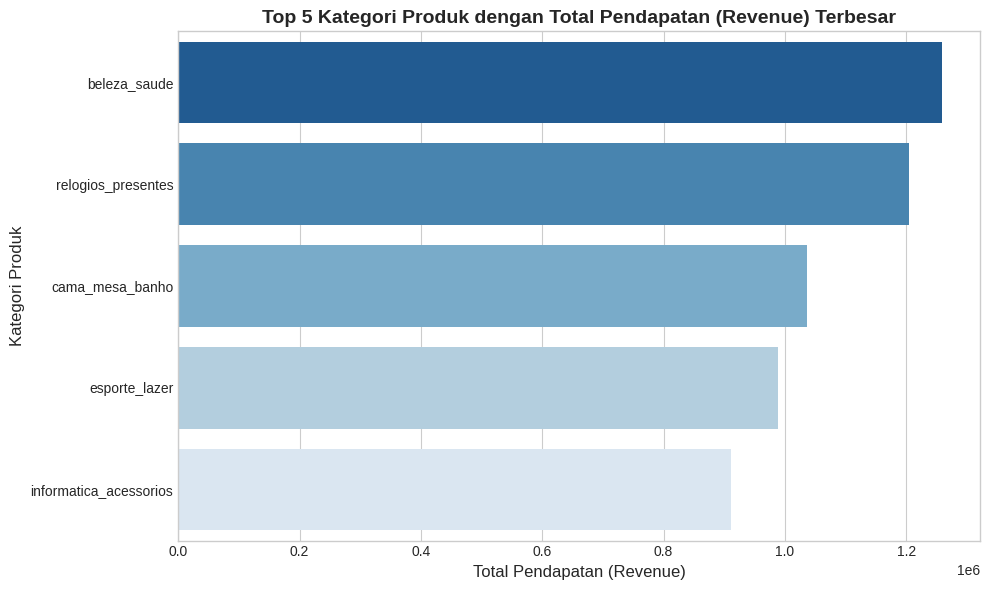

In [29]:
# Menyiapkan data Top 5 kategori dengan revenue terbesar
top_revenue_category = revenue_by_category.head(5)

# Membuat visualisasi bar chart
plt.figure(figsize=(10, 6))
sns.barplot(
    x='price',
    y='product_category_name',
    data=top_revenue_category,
    palette='Blues_r'
)

plt.title("Top 5 Kategori Produk dengan Total Pendapatan (Revenue) Terbesar", fontsize=14, fontweight='bold')
plt.xlabel("Total Pendapatan (Revenue)", fontsize=12)
plt.ylabel("Kategori Produk", fontsize=12)
plt.tight_layout()
plt.show()

### Pertanyaan 2:

/tmp/ipykernel_2679/1554917811.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


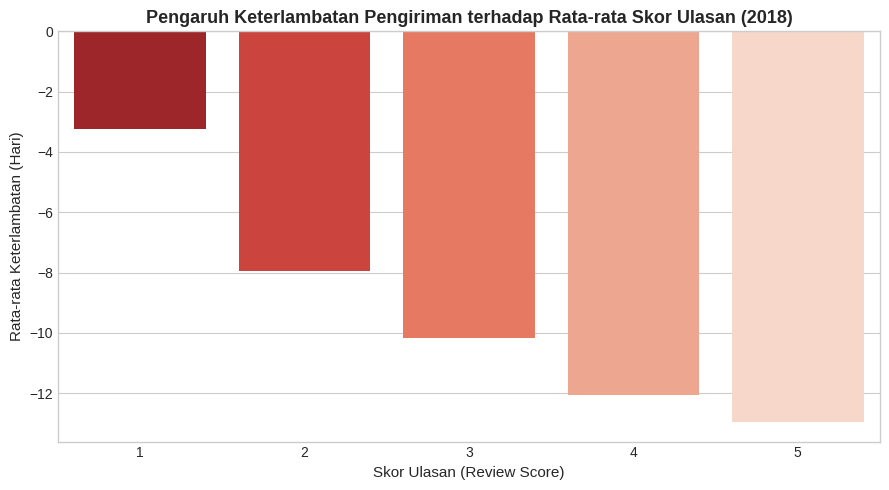

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Membuat visualisasi bar chart untuk Pertanyaan 2
plt.figure(figsize=(9, 5))
sns.barplot(
    x='review_score',
    y='delivery_latency',
    data=latency_vs_review,
    palette='Reds_r'
)

plt.title("Pengaruh Keterlambatan Pengiriman terhadap Rata-rata Skor Ulasan (2018)", fontsize=13, fontweight='bold')
plt.xlabel("Skor Ulasan (Review Score)", fontsize=11)
plt.ylabel("Rata-rata Keterlambatan (Hari)", fontsize=11)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)

Pertanyaan 1
- Penyumbang Pendapatan Terbesar (Top Categories): Kategori produk beleza_saude (Kecantikan & Kesehatan) menduduki peringkat pertama sebagai kategori yang menghasilkan total pendapatan (revenue) tertinggi, disusul dengan relogios_presentes (Jam Tangan & Hadiah) dan cama_mesa_banho (Perlengkapan Tidur & Mandi) dengan selisih nilai yang relatif kompetitif di kisaran angka 1 juta.
- Dominasi Sektor Gaya Hidup & Perawatan: Sebagian besar kategori produk dengan revenue tertinggi dikuasai oleh produk-produk yang berkaitan dengan perawatan diri, gaya hidup, serta perlengkapan rumah tangga, yang mencerminkan tingginya minat dan volume transaksi belanja konsumen pada sektor tersebut di platform e-commerce.
- Signifikansi Kontribusi Pasar: Lima kategori teratas menunjukkan performa penjualan yang sangat dominan dibanding kategori lainnya, memberikan arah strategis bagi manajemen untuk memprioritaskan pengelolaan stok dan promosi pada kategori-kategori utama tersebut guna memaksimalkan pendapatan bisnis.

Pertanyaan 2
- Berdasarkan visualisasi grafik, pesanan yang menerima skor ulasan tinggi (skor 4 dan 5) rata-rata dikirimkan jauh lebih awal dari tanggal estimasi (memiliki nilai delivery latency negatif, yaitu sekitar 12 hari lebih cepat dari estimasi yang dijanjikan).
- Sebaliknya, pesanan dengan skor ulasan rendah (skor 1 dan 2) memiliki selisih waktu pengiriman yang lebih mendekati tanggal estimasi atau tidak seawal pengiriman untuk skor ulasan sempurna.
- Temuan ini membuktikan secara visual bahwa kecepatan dan ketepatan waktu pengiriman (delivery performance) memegang peranan krusial terhadap kepuasan pelanggan di platform e-commerce. Semakin awal pesanan diterima oleh pelanggan dibandingkan estimasi waktu yang diberikan, semakin tinggi pula probabilitas pelanggan memberikan ulasan positif (skor 5).

## Analisis Lanjutan (Opsional)

/tmp/ipykernel_2679/2559271543.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='customer_count', y='customer_state', data=top_customers_state, palette='Purples_r')


--- TOP 5 NEGARA BAGIAN DENGAN PELANGGAN TERBANYAK ---
  customer_state  customer_count
0             SP           41746
1             RJ           12852
2             MG           11635
3             RS            5466
4             PR            5045


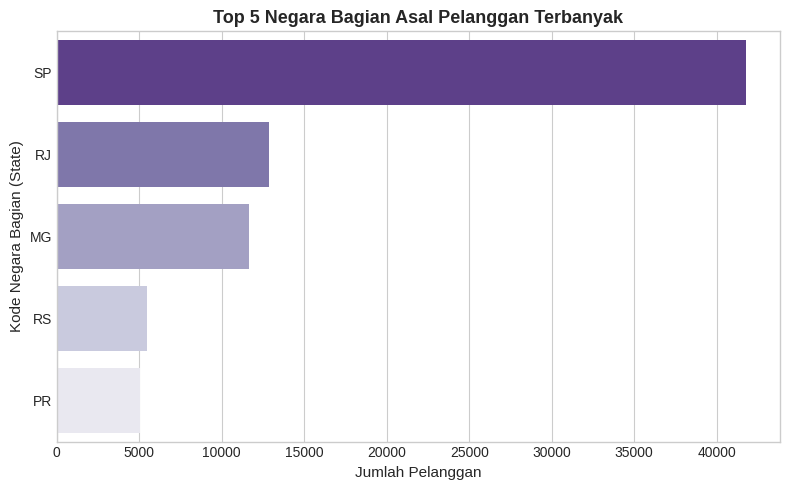

In [31]:
# Menghitung jumlah pelanggan per state (negara bagian)
top_customers_state = customers_df['customer_state'].value_counts().head(5).reset_index()
top_customers_state.columns = ['customer_state', 'customer_count']

print("--- TOP 5 NEGARA BAGIAN DENGAN PELANGGAN TERBANYAK ---")
print(top_customers_state)

# Visualisasi
plt.figure(figsize=(8, 5))
sns.barplot(x='customer_count', y='customer_state', data=top_customers_state, palette='Purples_r')
plt.title("Top 5 Negara Bagian Asal Pelanggan Terbanyak", fontsize=13, fontweight='bold')
plt.xlabel("Jumlah Pelanggan", fontsize=11)
plt.ylabel("Kode Negara Bagian (State)", fontsize=11)
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Dominasi Wilayah Utama (Top State): Berdasarkan distribusi asal pelanggan (customer_state), wilayah São Paulo (SP) menduduki peringkat pertama dengan jumlah pelanggan terbanyak secara signifikan (mencapai lebih dari 41.000 pelanggan), jauh melampaui wilayah-wilayah lainnya.
- Konsentrasi Pasar di Region Tenggara: Wilayah-wilayah seperti Rio de Janeiro (RJ) dan Minas Gerais (MG) menyusul di posisi kedua dan ketiga. Hal ini menunjukkan bahwa basis konsumen terbesar e-commerce ini terkonsentrasi di kawasan region utama/perkotaan besar Brasil.
- Implikasi Strategis: Konsentrasi pelanggan yang tinggi di wilayah tertentu memberikan panduan bagi manajemen untuk memprioritaskan efisiensi rantai pasok, penempatan gudang (fulfillment center), serta optimalisasi mitra logistik di area-area tersebut guna menekan durasi pengiriman.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kategori produk seperti beleza_saude (Kecantikan & Kesehatan), relogios_presentes (Jam Tangan & Hadiah), dan cama_mesa_banho (Perlengkapan Tidur & Mandi) menjadi tiga penyumbang pendapatan (revenue) terbesar sepanjang tahun 2018. Hal ini menunjukkan bahwa sektor perawatan diri, gaya hidup, dan perlengkapan rumah tangga mendominasi minat belanja konsumen di platform e-commerce.
- **Conclusion pertanyaan 2:** Terdapat korelasi yang kuat antara ketepatan waktu pengiriman dan kepuasan pelanggan. Pesanan yang menerima skor ulasan tertinggi (skor 4 dan 5) rata-rata dikirimkan jauh lebih awal dari estimasi waktu yang dijanjikan, sedangkan pesanan dengan rating rendah cenderung memiliki performa pengiriman yang kurang optimal.
- **Conclusion Analisis Lanjutan:** Berdasarkan distribusi geografis, wilayah São Paulo (SP), Rio de Janeiro (RJ), dan Minas Gerais (MG) menjadi pusat konsentrasi basis pelanggan terbesar (region tenggara Brasil), yang sangat memengaruhi efisiensi rantai pasok secara keseluruhan.

**Rekomendasi Action Item:**
- Optimalisasi Stok dan Promosi Kategori Utama: Manajemen perlu memprioritaskan pengelolaan inventaris, ketersediaan stok, dan program marketing campaign khusus untuk kategori produk terlaris (beleza_saude dan relogios_presentes) guna mendongkrak total pendapatan bisnis.
- Peningkatan Kinerja Logistik di Wilayah Utama: Mengingat konsentrasi pelanggan terbesar berada di wilayah São Paulo dan sekitarnya, perusahaan harus memperkuat kerja sama dengan mitra logistik lokal atau memperbanyak titik gudang (fulfillment center) di region tersebut untuk memastikan pengiriman selalu lebih cepat dari estimasi.